# Food Orders Data Analysis and ETL

This notebook completes Tasks 1–8. Each assignment question and subquestion appears in its own Markdown cell immediately followed by a separate code cell. The dataset is stored beside this notebook. Task 9 is in the Task_9_Pipeline folder.

## How to run

1. Open a terminal in the FoodOrders_ETL folder.
2. Install the notebook dependencies with: python -m pip install -r Task_9_Pipeline/requirements.txt
3. Start Jupyter with: jupyter notebook FoodOrders_Analysis.ipynb
4. In Jupyter, choose Kernel → Restart & Run All. Run every cell from top to bottom.
5. To run Task 9, start MySQL, set MYSQL_HOST, MYSQL_PORT, MYSQL_USER, and MYSQL_PASSWORD, then run: python Task_9_Pipeline/elt_batch_pipeline.py

The notebook saves the cleaned CSV, charts, rejection details, and validation report in the reports folder. Task 9 writes its execution and validation reports inside Task_9_Pipeline/reports.


## Task 1 — Load and understand the dataset

### Question 1.1 — Import the Python libraries required for data loading and analysis.

In [122]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd()
DATA_PATH = PROJECT_DIR / "food_orders.csv"
REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
if not DATA_PATH.exists():
    raise FileNotFoundError("Open/run this notebook from the FoodOrders_ETL folder containing food_orders.csv.")
print("Libraries loaded. Project folder:", PROJECT_DIR)

Libraries loaded. Project folder: /Users/adithyaadusumilli/Downloads/FoodOrders_ETL


### Question 1.2 — Load food_orders.csv into raw_df.

In [123]:
raw_df = pd.read_csv(DATA_PATH)
print(f"Loaded {len(raw_df):,} rows and {raw_df.shape[1]} columns from {DATA_PATH.name}.")

Loaded 1,010 rows and 14 columns from food_orders.csv.


### Question 1.3 — Display the first five rows.

In [124]:
print(raw_df.head(5).to_string(index=False))

 Order ID Customer ID Restaurant ID Order Date and Time Delivery Date and Time  Order Value  Delivery Fee   Payment Method Discounts and Offers  Commission Fee  Payment Processing Fee  Refunds/Chargebacks Weather Condition Order Channel
        1       C8270         R2924 2024-02-01 01:11:52    2024-02-01 02:39:52       1914.0           0.0      Credit Card            5% on App           150.0                    47.0                  0.0             Rainy    Mobile App
        2       C1860         R2054 2024-02-02 22:11:04    2024-02-02 22:46:04        986.0          40.0   Digital Wallet                  10%           198.0                    23.0                  0.0            Cloudy    Mobile App
        3       C6390         R2870 2024-01-31 05:54:35    2024-01-31 06:52:35        937.0          30.0 Cash on Delivery         15% New User           195.0                    45.0                  0.0             Humid    Mobile App
        4       C6191         R2642 2024-01-16 22:52

### Question 1.4 — Display the last five rows.

In [125]:
print(raw_df.tail(5).to_string(index=False))

 Order ID Customer ID Restaurant ID Order Date and Time Delivery Date and Time  Order Value  Delivery Fee   Payment Method Discounts and Offers  Commission Fee  Payment Processing Fee  Refunds/Chargebacks Weather Condition Order Channel
      208       C5736         R2750 2024-01-18 09:08:01    2024-01-18 09:49:01          NaN          50.0   Digital Wallet         50 off Promo           184.0                    41.0                  0.0             Rainy    Mobile App
      580       C8102         R2257 2024-01-03 08:46:06    2024-01-03 10:10:06       1045.0          40.0 Cash on Delivery                  10%           137.0                    13.0                  0.0             Sunny   Partner App
      497       C9010         R2462 2024-02-04 13:07:32    2024-02-04 14:25:32       1125.0           0.0      Credit Card                  10%            95.0                    16.0                 50.0            Cloudy   Partner App
      197       C2986         R2097 2024-01-16 13:11

### Question 1.5 — Display a random sample of five rows.

In [126]:
print(raw_df.sample(n=min(5, len(raw_df)), random_state=42).to_string(index=False))

 Order ID Customer ID Restaurant ID Order Date and Time Delivery Date and Time  Order Value  Delivery Fee   Payment Method Discounts and Offers  Commission Fee  Payment Processing Fee  Refunds/Chargebacks Weather Condition Order Channel
      630       C1716         R2905 2024-01-13 04:16:47    2024-01-13 06:09:47          NaN           0.0 Cash on Delivery            5% on App            91.0                    42.0                100.0             Rainy    Mobile App
      789       C9659         R2778 2024-01-31 10:35:46    2024-01-31 12:07:46        714.0          40.0 Cash on Delivery                  NaN           178.0                    25.0                150.0             Rainy   Partner App
      685       C7254         R2538 2024-01-07 23:31:43    2024-01-08 01:04:43        204.0          40.0   Digital Wallet                  NaN           195.0                    11.0                  0.0            Cloudy    Mobile App
      517       C8494         R2687 2024-01-23 05:41

### Question 1.6 — Display the number of rows and columns.

In [127]:
print(f"Rows: {raw_df.shape[0]:,}")
print(f"Columns: {raw_df.shape[1]:,}")

Rows: 1,010
Columns: 14


### Question 1.7 — Display the column names.

In [128]:
for number, column in enumerate(raw_df.columns, start=1):
    print(f"{number}. {column}")

1. Order ID
2. Customer ID
3. Restaurant ID
4. Order Date and Time
5. Delivery Date and Time
6. Order Value
7. Delivery Fee
8. Payment Method
9. Discounts and Offers
10. Commission Fee
11. Payment Processing Fee
12. Refunds/Chargebacks
13. Weather Condition
14. Order Channel


### Question 1.8 — Display the current data type of every column.

In [129]:
print(raw_df.dtypes.to_string())

Order ID                    int64
Customer ID                   str
Restaurant ID                 str
Order Date and Time           str
Delivery Date and Time        str
Order Value               float64
Delivery Fee              float64
Payment Method                str
Discounts and Offers          str
Commission Fee            float64
Payment Processing Fee    float64
Refunds/Chargebacks       float64
Weather Condition             str
Order Channel                 str


### Question 1.9 — Summarize the numeric columns.

In [130]:
print(raw_df.describe(include=[np.number]).round(2).to_string())

       Order ID  Order Value  Delivery Fee  Commission Fee  Payment Processing Fee  Refunds/Chargebacks
count   1010.00       969.00        960.00          970.00                  959.00               970.00
mean     499.22      1055.90         28.62          127.04                   29.90                27.89
std      288.59       529.53         16.93           43.01                   11.73                49.38
min        1.00       104.00          0.00           50.00                   10.00                 0.00
25%      248.25       600.00         20.00           90.25                   20.00                 0.00
50%      498.50      1041.00         30.00          128.00                   30.00                 0.00
75%      748.75      1494.00         40.00          164.00                   40.00                50.00
max     1000.00      1995.00         50.00          200.00                   50.00               150.00


### Question 1.10 — Summarize the categorical columns.

In [131]:
print(raw_df.describe(include=["object"]).to_string())

       Customer ID Restaurant ID  Order Date and Time Delivery Date and Time    Payment Method Discounts and Offers Weather Condition Order Channel
count         1010          1010                 1010                   1010               960                  768              1010          1010
unique         947           621                 1000                   1000                 3                    4                 4             3
top          C7949         R2317  2024-02-05 05:55:15    2024-02-05 07:33:15  Cash on Delivery                  10%             Sunny    Mobile App
freq             3             6                    2                      2               341                  221               405           693


/var/folders/jh/ybcx30qd2hgbzb1knm3y4bsc0000gn/T/ipykernel_5367/668983387.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(raw_df.describe(include=["object"]).to_string())


### Question 1.11 — Describe each column and its expected data type.

In [132]:
column_guide = pd.DataFrame([
    ("Order ID", "Order/transaction key", "identifier"),
    ("Customer ID", "Customer key", "identifier"),
    ("Restaurant ID", "Restaurant key", "identifier"),
    ("Order Date and Time", "Order placement timestamp", "datetime"),
    ("Delivery Date and Time", "Delivery completion timestamp", "datetime"),
    ("Order Value", "Order monetary value", "numeric"),
    ("Delivery Fee", "Delivery fee amount", "numeric"),
    ("Payment Method", "Customer payment type", "category"),
    ("Discounts and Offers", "Promotion description", "category"),
    ("Commission Fee", "Platform commission amount", "numeric"),
    ("Payment Processing Fee", "Payment processing cost", "numeric"),
    ("Refunds/Chargebacks", "Refund or chargeback amount", "numeric"),
    ("Weather Condition", "Weather at order time", "category"),
    ("Order Channel", "Ordering channel", "category"),
], columns=["Column", "Information represented", "Expected type"])
print(column_guide.to_string(index=False))

                Column       Information represented Expected type
              Order ID         Order/transaction key    identifier
           Customer ID                  Customer key    identifier
         Restaurant ID                Restaurant key    identifier
   Order Date and Time     Order placement timestamp      datetime
Delivery Date and Time Delivery completion timestamp      datetime
           Order Value          Order monetary value       numeric
          Delivery Fee           Delivery fee amount       numeric
        Payment Method         Customer payment type      category
  Discounts and Offers         Promotion description      category
        Commission Fee    Platform commission amount       numeric
Payment Processing Fee       Payment processing cost       numeric
   Refunds/Chargebacks   Refund or chargeback amount       numeric
     Weather Condition         Weather at order time      category
         Order Channel              Ordering channel      cate

### Question 1.12 — State what one row represents and identify columns useful for order value, delivery, payments, and platform revenue.

In [133]:
print("One row represents one food order transaction.")
print("Order value: Order Value. Delivery: Order Date and Time and Delivery Date and Time.")
print("Payments: Payment Method. Simplified platform net revenue: Commission Fee, Delivery Fee, Payment Processing Fee, and Refunds/Chargebacks.")
print("The revenue measure is the assignment formula, not a full accounting definition.")

One row represents one food order transaction.
Order value: Order Value. Delivery: Order Date and Time and Delivery Date and Time.
Payments: Payment Method. Simplified platform net revenue: Commission Fee, Delivery Fee, Payment Processing Fee, and Refunds/Chargebacks.
The revenue measure is the assignment formula, not a full accounting definition.


## Task 2 — Perform a data-quality assessment

### Question 2.1 — Count the missing values in each column.

In [134]:
missing_counts = raw_df.isna().sum()
print(missing_counts.to_string())

Order ID                    0
Customer ID                 0
Restaurant ID               0
Order Date and Time         0
Delivery Date and Time      0
Order Value                41
Delivery Fee               50
Payment Method             50
Discounts and Offers      242
Commission Fee             40
Payment Processing Fee     51
Refunds/Chargebacks        40
Weather Condition           0
Order Channel               0


### Question 2.2 — Calculate the percentage of missing values in each column.

In [135]:
missing_percent = (raw_df.isna().mean() * 100).round(2)
print(missing_percent.to_string())

Order ID                   0.00
Customer ID                0.00
Restaurant ID              0.00
Order Date and Time        0.00
Delivery Date and Time     0.00
Order Value                4.06
Delivery Fee               4.95
Payment Method             4.95
Discounts and Offers      23.96
Commission Fee             3.96
Payment Processing Fee     5.05
Refunds/Chargebacks        3.96
Weather Condition          0.00
Order Channel              0.00


### Question 2.3 — Count fully duplicated rows.

In [136]:
exact_duplicate_count = int(raw_df.duplicated().sum())
print(f"Fully duplicated rows (excluding each first occurrence): {exact_duplicate_count}")

Fully duplicated rows (excluding each first occurrence): 10


### Question 2.4 — Check whether Order ID values repeat before deciding what to remove.

In [137]:
repeated_id_mask_raw = raw_df["Order ID"].duplicated(keep=False)
repeated_id_frequencies_raw = raw_df.loc[repeated_id_mask_raw, "Order ID"].value_counts().sort_index()
print(f"Rows with a repeated Order ID: {int(repeated_id_mask_raw.sum())}")
print(repeated_id_frequencies_raw.to_string() if len(repeated_id_frequencies_raw) else "No repeated Order IDs.")

Rows with a repeated Order ID: 20
Order ID
122    2
133    2
156    2
197    2
208    2
419    2
497    2
571    2
580    2
831    2


### Question 2.5 — Identify columns with unexpected pre-cleaning data types.

In [138]:
financial_columns = ["Order Value", "Delivery Fee", "Commission Fee", "Payment Processing Fee", "Refunds/Chargebacks"]
timestamp_columns = ["Order Date and Time", "Delivery Date and Time"]
unexpected_type_notes = []
for column in timestamp_columns:
    if not pd.api.types.is_datetime64_any_dtype(raw_df[column]):
        unexpected_type_notes.append(f"{column}: stored as {raw_df[column].dtype}; expected datetime after parsing.")
for column in financial_columns:
    if not pd.api.types.is_numeric_dtype(raw_df[column]):
        unexpected_type_notes.append(f"{column}: stored as {raw_df[column].dtype}; expected numeric.")
print("\n".join(unexpected_type_notes) if unexpected_type_notes else "No unexpected types found.")
print("Order ID is an identifier; its numeric storage does not make it a measure.")

Order Date and Time: stored as str; expected datetime after parsing.
Delivery Date and Time: stored as str; expected datetime after parsing.
Order ID is an identifier; its numeric storage does not make it a measure.


### Question 2.6 — Check whether order and delivery timestamps parse as datetime values.

In [139]:
parsed_order = pd.to_datetime(raw_df["Order Date and Time"], errors="coerce")
parsed_delivery = pd.to_datetime(raw_df["Delivery Date and Time"], errors="coerce")
print("Invalid order timestamps:", int(parsed_order.isna().sum()))
print("Invalid delivery timestamps:", int(parsed_delivery.isna().sum()))

Invalid order timestamps: 0
Invalid delivery timestamps: 0


### Question 2.7 — Count records where delivery occurs before the order.

In [140]:
raw_duration = (parsed_delivery - parsed_order).dt.total_seconds() / 60
before_order_mask = raw_duration.lt(0).fillna(False)
print("Delivery-before-order records:", int(before_order_mask.sum()))

Delivery-before-order records: 0


### Question 2.8 — Check for negative or suspicious financial values and delivery durations.

In [141]:
financial_numeric = raw_df[financial_columns].apply(pd.to_numeric, errors="coerce")
print("Negative financial values by column:")
print(financial_numeric.lt(0).sum().to_string())
print("Negative delivery durations:", int(raw_duration.lt(0).sum()))
print("Delivery durations over 240 minutes (review-screen assumption):", int(raw_duration.gt(240).sum()))
print("Duration summary in minutes:")
print(raw_duration.describe().round(2).to_string())

Negative financial values by column:
Order Value               0
Delivery Fee              0
Commission Fee            0
Payment Processing Fee    0
Refunds/Chargebacks       0
Negative delivery durations: 0
Delivery durations over 240 minutes (review-screen assumption): 0
Duration summary in minutes:
count    1010.00
mean       73.61
std        25.97
min        30.00
25%        50.00
50%        74.00
75%        96.00
max       119.00


### Question 2.9a — Show distinct values and frequencies for Payment Method.

In [142]:
print(raw_df["Payment Method"].value_counts(dropna=False).to_string())

Payment Method
Cash on Delivery    341
Credit Card         323
Digital Wallet      296
NaN                  50


### Question 2.9b — Show distinct values and frequencies for Discounts and Offers.

In [143]:
print(raw_df["Discounts and Offers"].value_counts(dropna=False).to_string())

Discounts and Offers
NaN             242
10%             221
50 off Promo    194
15% New User    183
5% on App       170


### Question 2.9c — Show distinct values and frequencies for Weather Condition.

In [144]:
print(raw_df["Weather Condition"].value_counts(dropna=False).to_string())

Weather Condition
Sunny     405
Cloudy    252
Rainy     202
Humid     151


### Question 2.9d — Show distinct values and frequencies for Order Channel.

In [145]:
print(raw_df["Order Channel"].value_counts(dropna=False).to_string())

Order Channel
Mobile App     693
Partner App    165
Website        152


### Task 2 deliverable — Data-quality issues and business impact

### Question 2.10 — Summarize at least three measured data-quality issues and explain why they matter.


In [146]:
quality_findings = [
    (f"{exact_duplicate_count} exact duplicate rows", "Can inflate order counts and financial totals."),
    (f"{int(raw_df['Order Value'].isna().sum())} missing Order Value values", "Cannot be included in valid order-value totals or averages."),
    (f"{int(raw_df['Payment Method'].isna().sum())} missing payment methods", "Makes the payment mix incomplete unless unknown values remain visible."),
    (f"{int(raw_df['Discounts and Offers'].isna().sum())} missing offer descriptions", "Promotion attribution is incomplete; missing does not prove no offer."),
    (f"{int(raw_df[['Delivery Fee','Commission Fee','Payment Processing Fee','Refunds/Chargebacks']].isna().sum().sum())} missing fee/refund component cells", "Limits the number of orders eligible for the platform net revenue calculation."),
]
for issue, impact in quality_findings:
    print(f"{issue}: {impact}")

10 exact duplicate rows: Can inflate order counts and financial totals.
41 missing Order Value values: Cannot be included in valid order-value totals or averages.
50 missing payment methods: Makes the payment mix incomplete unless unknown values remain visible.
242 missing offer descriptions: Promotion attribution is incomplete; missing does not prove no offer.
181 missing fee/refund component cells: Limits the number of orders eligible for the platform net revenue calculation.


## Task 3 — Design and document cleaning rules before changing data

| Data-quality issue | Chosen handling rule | Reason / business assumption |
|---|---|---|
| Exact duplicate rows | Keep originals in the raw layer; remove one copy during analysis after inspecting the duplicate rows. Compare every source field. | Exact repeated source rows can inflate order counts and revenue.
| Repeated Order ID | Check after exact duplicates are removed. Retain distinct rows with repeated IDs and flag for investigation. | A repeated key alone does not prove two records are identical.
| Missing Order Value | Retain as missing and exclude from order-value metrics. | No defensible replacement is available in the data.
| Missing Delivery Fee, Commission Fee, Payment Processing Fee, or Refunds/Chargebacks | Retain as missing; do not replace with zero. | Zero would assert a known amount and could bias financial results.
| Missing Payment Method | Use Unknown. | Keeps orders in the dataset without guessing the payment type.
| Missing Discounts and Offers | Use Not Specified. | Does not claim that no offer was applied.
| Invalid or missing timestamps | Parse with errors coerced to missing; exclude from duration analysis when either timestamp is invalid. | Invalid timestamps cannot support a valid delivery duration.
| Negative delivery duration | Flag and exclude from valid-duration records; preserve the original in raw data. | Delivery before order is not operationally valid without correction evidence.
| Duration over 240 minutes | Flag for review and retain. This 240-minute screen is an explicit analysis assumption, not an SLA in the assignment. | Avoids silently discarding potentially real long deliveries.


## Task 4 — Clean the dataset

### Question 4.1 — Create work_df as a separate copy, inspect exact duplicates, then remove exact duplicates.

In [147]:
work_df = raw_df.copy(deep=True)
original_row_count = len(work_df)
exact_duplicate_mask = work_df.duplicated(keep="first")
duplicate_rows = work_df.loc[exact_duplicate_mask].copy()
duplicate_rows["rejection_reason"] = "exact_duplicate_source_row"
exact_duplicate_rows_removed = int(exact_duplicate_mask.sum())
work_df = work_df.loc[~exact_duplicate_mask].copy()
print(f"Inspected and removed {exact_duplicate_rows_removed} exact duplicate rows.")
print("raw_df remains unchanged:", len(raw_df) == original_row_count)

Inspected and removed 10 exact duplicate rows.
raw_df remains unchanged: True


### Question 4.2 — Recheck repeated Order ID values and decide how to handle them.

In [148]:
repeated_id_mask_cleaning = work_df["Order ID"].duplicated(keep=False)
repeated_ids_after_exact_dedup = work_df.loc[repeated_id_mask_cleaning, "Order ID"].value_counts().sort_index()
print("Repeated Order ID frequencies after exact duplicate removal:")
print(repeated_ids_after_exact_dedup.to_string() if len(repeated_ids_after_exact_dedup) else "None remain.")
print("Rule: retain any distinct rows sharing an ID and investigate; do not delete them by ID alone.")

Repeated Order ID frequencies after exact duplicate removal:
None remain.
Rule: retain any distinct rows sharing an ID and investigate; do not delete them by ID alone.


### Question 4.3 — Convert order and delivery timestamps to datetime, handling parsing errors explicitly.

In [149]:
for column in ["Order Date and Time", "Delivery Date and Time"]:
    work_df[column] = pd.to_datetime(work_df[column], errors="coerce")
invalid_timestamp_mask = work_df[["Order Date and Time", "Delivery Date and Time"]].isna().any(axis=1)
invalid_timestamp_rows = work_df.loc[invalid_timestamp_mask].copy()
invalid_timestamp_rows_removed = int(invalid_timestamp_mask.sum())
print("Invalid or missing timestamp rows after parsing:", invalid_timestamp_rows_removed)

Invalid or missing timestamp rows after parsing: 0


### Question 4.4 — Convert financial columns to appropriate numeric types.

In [150]:
for column in financial_columns:
    work_df[column] = pd.to_numeric(work_df[column], errors="coerce")
print(work_df[financial_columns].dtypes.to_string())
print("Missing financial values were kept as missing; no zero imputation was applied.")

Order Value               float64
Delivery Fee              float64
Commission Fee            float64
Payment Processing Fee    float64
Refunds/Chargebacks       float64
Missing financial values were kept as missing; no zero imputation was applied.


### Question 4.5 — Apply the documented cleaning rules, including invalid timestamps and impossible durations.

In [151]:
parsed_duration_for_cleaning = (work_df["Delivery Date and Time"] - work_df["Order Date and Time"]).dt.total_seconds() / 60
negative_duration_mask_cleaning = parsed_duration_for_cleaning.lt(0).fillna(False)
invalid_record_mask = invalid_timestamp_mask | negative_duration_mask_cleaning
invalid_records = work_df.loc[invalid_record_mask].copy()
invalid_records["rejection_reason"] = np.where(
    invalid_timestamp_mask.loc[invalid_records.index], "invalid_or_missing_timestamp", "negative_delivery_duration"
)
negative_duration_rows_removed = int((negative_duration_mask_cleaning & ~invalid_timestamp_mask).sum())
cleaned_df = work_df.loc[~invalid_record_mask].copy()
cleaned_df["Payment Method"] = cleaned_df["Payment Method"].fillna("Unknown")
cleaned_df["Discounts and Offers"] = cleaned_df["Discounts and Offers"].fillna("Not Specified")
print("Invalid timestamp rows removed:", invalid_timestamp_rows_removed)
print("Negative duration rows removed:", negative_duration_rows_removed)
print("Missing financial values retained:", int(cleaned_df[financial_columns].isna().sum().sum()))
print("Missing categories labeled Unknown / Not Specified.")

Invalid timestamp rows removed: 0
Negative duration rows removed: 0
Missing financial values retained: 220
Missing categories labeled Unknown / Not Specified.


### Question 4.6 — Track rows removed and retained, and explain why.

In [152]:
cleaning_audit = {
    "original_rows": original_row_count,
    "exact_duplicates_removed": exact_duplicate_rows_removed,
    "invalid_timestamp_rows_removed": invalid_timestamp_rows_removed,
    "negative_duration_rows_removed": negative_duration_rows_removed,
    "rows_retained": len(cleaned_df),
}
print(json.dumps(cleaning_audit, indent=2))
print("Duplicate rows were removed to prevent double counting; invalid timestamps/negative durations cannot support valid delivery-time analysis.")

{
  "original_rows": 1010,
  "exact_duplicates_removed": 10,
  "invalid_timestamp_rows_removed": 0,
  "negative_duration_rows_removed": 0,
  "rows_retained": 1000
}
Duplicate rows were removed to prevent double counting; invalid timestamps/negative durations cannot support valid delivery-time analysis.


### Question 4.7 — Display the first five cleaned rows, data types, and remaining missing values.

In [153]:
print("First five cleaned rows:")
print(cleaned_df.head().to_string(index=False))
print("\nData types:")
print(cleaned_df.dtypes.to_string())
print("\nMissing values retained:")
print(cleaned_df.isna().sum().to_string())

First five cleaned rows:
 Order ID Customer ID Restaurant ID Order Date and Time Delivery Date and Time  Order Value  Delivery Fee   Payment Method Discounts and Offers  Commission Fee  Payment Processing Fee  Refunds/Chargebacks Weather Condition Order Channel
        1       C8270         R2924 2024-02-01 01:11:52    2024-02-01 02:39:52       1914.0           0.0      Credit Card            5% on App           150.0                    47.0                  0.0             Rainy    Mobile App
        2       C1860         R2054 2024-02-02 22:11:04    2024-02-02 22:46:04        986.0          40.0   Digital Wallet                  10%           198.0                    23.0                  0.0            Cloudy    Mobile App
        3       C6390         R2870 2024-01-31 05:54:35    2024-01-31 06:52:35        937.0          30.0 Cash on Delivery         15% New User           195.0                    45.0                  0.0             Humid    Mobile App
        4       C6191      

**Task 4 interpretation:** Missing Order Value and fee/refund values remain missing because there is no evidence for replacement amounts. Payment Method and offer blanks use the documented labels. The row counts above distinguish duplicate removal from records excluded for invalid delivery timing.

## Task 5 — Transform the data and create derived columns

### Question 5.1 — Create Delivery_Time_Minutes from the two timestamps.

In [154]:
cleaned_df["Delivery_Time_Minutes"] = (
    cleaned_df["Delivery Date and Time"] - cleaned_df["Order Date and Time"]
).dt.total_seconds() / 60
print(cleaned_df[["Order ID", "Delivery_Time_Minutes"]].head().to_string(index=False))

 Order ID  Delivery_Time_Minutes
        1                   88.0
        2                   35.0
        3                   58.0
        4                   46.0
        5                   89.0


### Question 5.2 — Create Order_Date from the order timestamp.

In [155]:
cleaned_df["Order_Date"] = cleaned_df["Order Date and Time"].dt.date
print(cleaned_df[["Order ID", "Order Date and Time", "Order_Date"]].head().to_string(index=False))

 Order ID Order Date and Time Order_Date
        1 2024-02-01 01:11:52 2024-02-01
        2 2024-02-02 22:11:04 2024-02-02
        3 2024-01-31 05:54:35 2024-01-31
        4 2024-01-16 22:52:49 2024-01-16
        5 2024-01-29 01:19:30 2024-01-29


### Question 5.3 — Create Order_Hour from the order timestamp.

In [156]:
cleaned_df["Order_Hour"] = cleaned_df["Order Date and Time"].dt.hour.astype("Int64")
print(cleaned_df[["Order ID", "Order Date and Time", "Order_Hour"]].head().to_string(index=False))

 Order ID Order Date and Time  Order_Hour
        1 2024-02-01 01:11:52           1
        2 2024-02-02 22:11:04          22
        3 2024-01-31 05:54:35           5
        4 2024-01-16 22:52:49          22
        5 2024-01-29 01:19:30           1


### Question 5.4 — Calculate Platform_Net_Revenue only when all four required components are available.

In [157]:
required_revenue_components = ["Commission Fee", "Delivery Fee", "Payment Processing Fee", "Refunds/Chargebacks"]
revenue_components_complete = cleaned_df[required_revenue_components].notna().all(axis=1)
revenue_formula = (
    cleaned_df["Commission Fee"] + cleaned_df["Delivery Fee"]
    - cleaned_df["Payment Processing Fee"] - cleaned_df["Refunds/Chargebacks"]
)
cleaned_df["Platform_Net_Revenue"] = revenue_formula.where(revenue_components_complete)
print("Rows with all components:", int(revenue_components_complete.sum()))
print("Rows with missing revenue:", int(cleaned_df["Platform_Net_Revenue"].isna().sum()))
print(cleaned_df[["Order ID", "Platform_Net_Revenue"]].head().to_string(index=False))

Rows with all components: 828
Rows with missing revenue: 172
 Order ID  Platform_Net_Revenue
        1                 103.0
        2                 215.0
        3                 180.0
        4                   NaN
        5                   NaN


### Question 5.5 — Identify records that cannot have a delivery duration calculated and explain why.

In [158]:
missing_duration_mask = cleaned_df["Delivery_Time_Minutes"].isna()
print("Missing duration records in cleaned data:", int(missing_duration_mask.sum()))
print("Rows removed for invalid/missing timestamps:", invalid_timestamp_rows_removed)
print("Reason: the duration requires both a parseable order timestamp and a parseable delivery timestamp.")

Missing duration records in cleaned data: 0
Rows removed for invalid/missing timestamps: 0
Reason: the duration requires both a parseable order timestamp and a parseable delivery timestamp.


### Question 5.6 — Flag and investigate negative or implausible delivery durations.

In [159]:
negative_duration_remaining = cleaned_df["Delivery_Time_Minutes"].lt(0)
implausible_duration_mask = cleaned_df["Delivery_Time_Minutes"].gt(240)
cleaned_df["Delivery_Quality_Flag"] = np.where(implausible_duration_mask, "review_implausibly_long", "valid")
print("Negative durations remaining:", int(negative_duration_remaining.sum()))
print("Durations over 240 minutes flagged for review:", int(implausible_duration_mask.sum()))
print(cleaned_df.loc[implausible_duration_mask, ["Order ID", "Delivery_Time_Minutes", "Delivery_Quality_Flag"]].to_string(index=False))

Negative durations remaining: 0
Durations over 240 minutes flagged for review: 0
Empty DataFrame
Columns: [Order ID, Delivery_Time_Minutes, Delivery_Quality_Flag]
Index: []


### Question 5.7 — Explain why missing revenue components must not automatically become zero.

In [160]:
missing_revenue_records = int(cleaned_df["Platform_Net_Revenue"].isna().sum())
print(f"{missing_revenue_records} records have no calculated Platform_Net_Revenue because one or more formula components are missing.")
print("Replacing an unknown fee/refund with zero would assert a known amount and could bias the result.")

172 records have no calculated Platform_Net_Revenue because one or more formula components are missing.
Replacing an unknown fee/refund with zero would assert a known amount and could bias the result.


## Task 6 — Answer the business questions

### Question 6.1 — How many records were in the original data and how many remain after cleaning?

In [161]:
print(f"Original records: {len(raw_df):,}")
print(f"Cleaned records: {len(cleaned_df):,}")

Original records: 1,010
Cleaned records: 1,000


### Question 6.2 — How many records have a valid Order Value?

In [162]:
valid_order_values = cleaned_df["Order Value"].dropna()
print(f"Valid Order Value records: {len(valid_order_values):,} of {len(cleaned_df):,} cleaned records.")

Valid Order Value records: 960 of 1,000 cleaned records.


### Question 6.3 — What are the total, mean, and median Order Values for valid records?

In [163]:
print(f"Records included: {valid_order_values.count():,}")
print(f"Total Order Value: {valid_order_values.sum():,.2f}")
print(f"Mean Order Value: {valid_order_values.mean():,.4f}")
print(f"Median Order Value: {valid_order_values.median():,.2f}")

Records included: 960
Total Order Value: 1,013,415.00
Mean Order Value: 1,055.6406
Median Order Value: 1,040.00


### Question 6.4 — Which known Payment Method has the largest order count?

In [164]:
known_payment = cleaned_df.loc[cleaned_df["Payment Method"].ne("Unknown"), "Payment Method"]
payment_counts = known_payment.value_counts()
print(payment_counts.to_string())
print(f"Largest known payment method: {payment_counts.idxmax()} ({int(payment_counts.max())} orders).")

Payment Method
Cash on Delivery    336
Credit Card         320
Digital Wallet      294
Largest known payment method: Cash on Delivery (336 orders).


### Question 6.5 — Which Order Channel has the most orders?

In [165]:
channel_counts = cleaned_df["Order Channel"].value_counts(dropna=False)
print(channel_counts.to_string())
print(f"Most orders: {channel_counts.idxmax()} ({int(channel_counts.max())} orders).")

Order Channel
Mobile App     686
Partner App    162
Website        152
Most orders: Mobile App (686 orders).


### Question 6.6 — Which Weather Condition appears most frequently?

In [166]:
weather_counts = cleaned_df["Weather Condition"].value_counts(dropna=False)
print(weather_counts.to_string())
print(f"Most frequent weather condition: {weather_counts.idxmax()} ({int(weather_counts.max())} orders).")

Weather Condition
Sunny     402
Cloudy    247
Rainy     200
Humid     151
Most frequent weather condition: Sunny (402 orders).


### Question 6.7 — What are the mean and median valid delivery times?

In [167]:
valid_delivery_times = cleaned_df["Delivery_Time_Minutes"].dropna()
print(f"Records included: {valid_delivery_times.count():,}")
print(f"Mean delivery time: {valid_delivery_times.mean():.3f} minutes")
print(f"Median delivery time: {valid_delivery_times.median():.2f} minutes")

Records included: 1,000
Mean delivery time: 73.575 minutes
Median delivery time: 74.00 minutes


### Question 6.8 — Which five restaurants have the highest order counts?

In [168]:
restaurant_counts = cleaned_df["Restaurant ID"].value_counts().head(5)
print(restaurant_counts.to_string())

Restaurant ID
R2317    6
R2804    5
R2726    5
R2016    5
R2523    5


### Question 6.9 — What is total Platform_Net_Revenue, and how many records are included?

In [169]:
valid_revenue = cleaned_df["Platform_Net_Revenue"].dropna()
print(f"Records included with all four required components: {valid_revenue.count():,}")
print(f"Total Platform_Net_Revenue: {valid_revenue.sum():,.2f}")
print("Order value metrics use non-missing Order Value rows; the revenue metric uses only complete formula rows.")

Records included with all four required components: 828
Total Platform_Net_Revenue: 80,877.00
Order value metrics use non-missing Order Value rows; the revenue metric uses only complete formula rows.


## Task 7 — Create and explain visualizations

### Question 7.1 — Chart order counts by Order Channel and explain what the chart suggests.

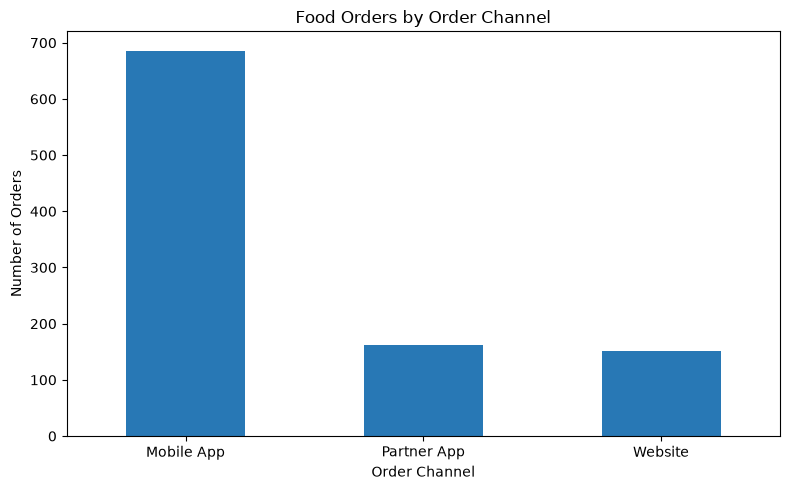

The highest observed channel is Mobile App with 686 orders. This is descriptive, not causal.


In [170]:
channel_chart_counts = cleaned_df["Order Channel"].value_counts().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
channel_chart_counts.plot(kind="bar", ax=ax, color="#2878B5")
ax.set_title("Food Orders by Order Channel")
ax.set_xlabel("Order Channel")
ax.set_ylabel("Number of Orders")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(REPORT_DIR / "orders_by_channel.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"The highest observed channel is {channel_chart_counts.idxmax()} with {int(channel_chart_counts.max())} orders. This is descriptive, not causal.")

### Question 7.2 — Chart average delivery time by Weather Condition and explain what the chart suggests.

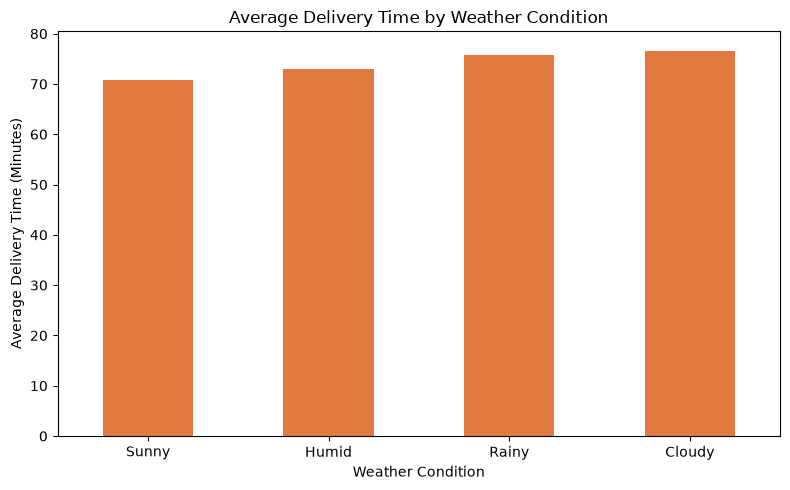

Observed means range from Sunny (70.84 min) to Cloudy (76.63 min). The chart does not establish that weather caused the difference.


In [171]:
weather_delivery = cleaned_df.dropna(subset=["Delivery_Time_Minutes"]).groupby("Weather Condition")["Delivery_Time_Minutes"].mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
weather_delivery.plot(kind="bar", ax=ax, color="#E07A3F")
ax.set_title("Average Delivery Time by Weather Condition")
ax.set_xlabel("Weather Condition")
ax.set_ylabel("Average Delivery Time (Minutes)")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(REPORT_DIR / "average_delivery_by_weather.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Observed means range from {weather_delivery.idxmin()} ({weather_delivery.min():.2f} min) to {weather_delivery.idxmax()} ({weather_delivery.max():.2f} min). The chart does not establish that weather caused the difference.")

## Task 8 — Validate the transformed dataset

### Question 8.1 — Check that the cleaned dataset has the expected columns.

In [172]:
expected_source_columns = [
    "Order ID", "Customer ID", "Restaurant ID", "Order Date and Time", "Delivery Date and Time",
    "Order Value", "Delivery Fee", "Payment Method", "Discounts and Offers", "Commission Fee",
    "Payment Processing Fee", "Refunds/Chargebacks", "Weather Condition", "Order Channel",
]
expected_derived_columns = ["Delivery_Time_Minutes", "Order_Date", "Order_Hour", "Platform_Net_Revenue"]
missing_expected_columns = sorted(set(expected_source_columns + expected_derived_columns) - set(cleaned_df.columns))
print("Missing expected columns:", missing_expected_columns)
columns_check = not missing_expected_columns

Missing expected columns: []


### Question 8.2 — Check datetime and financial data types.

In [173]:
datetime_types_valid = all(pd.api.types.is_datetime64_any_dtype(cleaned_df[c]) for c in ["Order Date and Time", "Delivery Date and Time"])
numeric_types_valid = all(pd.api.types.is_numeric_dtype(cleaned_df[c]) for c in financial_columns + ["Delivery_Time_Minutes", "Platform_Net_Revenue"])
print("Datetime columns valid:", datetime_types_valid)
print("Financial and derived numeric columns valid:", numeric_types_valid)
print(cleaned_df[["Order Date and Time", "Delivery Date and Time"] + financial_columns + ["Delivery_Time_Minutes", "Platform_Net_Revenue"]].dtypes.to_string())

Datetime columns valid: True
Financial and derived numeric columns valid: True
Order Date and Time       datetime64[us]
Delivery Date and Time    datetime64[us]
Order Value                      float64
Delivery Fee                     float64
Commission Fee                   float64
Payment Processing Fee           float64
Refunds/Chargebacks              float64
Delivery_Time_Minutes            float64
Platform_Net_Revenue             float64


### Question 8.3 — Verify fully duplicated rows were handled according to the rules.

In [174]:
exact_duplicates_remaining = int(cleaned_df.duplicated(subset=expected_source_columns).sum())
print("Exact duplicate rows removed:", exact_duplicate_rows_removed)
print("Exact duplicate rows remaining in cleaned data:", exact_duplicates_remaining)
exact_duplicates_check = exact_duplicates_remaining == 0

Exact duplicate rows removed: 10
Exact duplicate rows remaining in cleaned data: 0


### Question 8.4 — Verify repeated Order IDs were checked and explain the result.

In [175]:
repeated_order_rows = int(cleaned_df["Order ID"].duplicated(keep=False).sum())
repeated_order_values = cleaned_df.loc[cleaned_df["Order ID"].duplicated(keep=False), "Order ID"].unique().tolist()
print("Repeated Order ID rows remaining:", repeated_order_rows)
print("Repeated IDs:", repeated_order_values)
print("Distinct repeated IDs are retained for investigation; exact duplicate rows were removed.")
repeated_ids_check = True

Repeated Order ID rows remaining: 0
Repeated IDs: []
Distinct repeated IDs are retained for investigation; exact duplicate rows were removed.


### Question 8.5 — Verify no negative delivery durations remain in valid rows and report flagged records.

In [176]:
negative_valid_durations = int(cleaned_df["Delivery_Time_Minutes"].lt(0).sum())
flagged_delivery_records = int(cleaned_df["Delivery_Quality_Flag"].ne("valid").sum())
print("Negative durations among valid rows:", negative_valid_durations)
print("Rows flagged for duration review:", flagged_delivery_records)
negative_duration_check = negative_valid_durations == 0

Negative durations among valid rows: 0
Rows flagged for duration review: 0


### Question 8.6 — Manually inspect a few delivery duration calculations.

In [177]:
manual_duration_rows = cleaned_df.dropna(subset=["Order Date and Time", "Delivery Date and Time"]).head(5).copy()
manual_duration_rows["duration_recomputed"] = (
    manual_duration_rows["Delivery Date and Time"] - manual_duration_rows["Order Date and Time"]
).dt.total_seconds() / 60
print(manual_duration_rows[["Order ID", "Delivery_Time_Minutes", "duration_recomputed"]].to_string(index=False))
manual_duration_check = bool(np.allclose(manual_duration_rows["Delivery_Time_Minutes"], manual_duration_rows["duration_recomputed"]))
print("Duration spot checks passed:", manual_duration_check)

 Order ID  Delivery_Time_Minutes  duration_recomputed
        1                   88.0                 88.0
        2                   35.0                 35.0
        3                   58.0                 58.0
        4                   46.0                 46.0
        5                   89.0                 89.0
Duration spot checks passed: True


### Question 8.7 — Manually inspect the revenue formula for a few eligible records.

In [178]:
manual_revenue_rows = cleaned_df.loc[revenue_components_complete].head(5).copy()
manual_revenue_rows["revenue_recomputed"] = (
    manual_revenue_rows["Commission Fee"] + manual_revenue_rows["Delivery Fee"]
    - manual_revenue_rows["Payment Processing Fee"] - manual_revenue_rows["Refunds/Chargebacks"]
)
print(manual_revenue_rows[["Order ID", "Platform_Net_Revenue", "revenue_recomputed"]].to_string(index=False))
manual_revenue_check = bool(np.allclose(manual_revenue_rows["Platform_Net_Revenue"], manual_revenue_rows["revenue_recomputed"]))
print("Revenue spot checks passed:", manual_revenue_check)

 Order ID  Platform_Net_Revenue  revenue_recomputed
        1                 103.0               103.0
        2                 215.0               215.0
        3                 180.0               180.0
        6                 -65.0               -65.0
        7                 112.0               112.0
Revenue spot checks passed: True


### Question 8.8 — Compare missing-value counts before and after cleaning.

In [179]:
missing_value_comparison = pd.DataFrame({
    "before_cleaning": raw_df[expected_source_columns].isna().sum(),
    "after_cleaning": cleaned_df[expected_source_columns].isna().sum(),
})
print(missing_value_comparison.to_string())
print("Remaining missing values are intentional for financial fields with unknown amounts.")

                        before_cleaning  after_cleaning
Order ID                              0               0
Customer ID                           0               0
Restaurant ID                         0               0
Order Date and Time                   0               0
Delivery Date and Time                0               0
Order Value                          41              40
Delivery Fee                         50              50
Payment Method                       50               0
Discounts and Offers                242               0
Commission Fee                       40              40
Payment Processing Fee               51              50
Refunds/Chargebacks                  40              40
Weather Condition                     0               0
Order Channel                         0               0
Remaining missing values are intentional for financial fields with unknown amounts.


### Question 8.9 — Report rows removed, retained, excluded from calculations, and the final validation status.

In [180]:
rejected_records = pd.concat([duplicate_rows, invalid_records], ignore_index=True, sort=False)
row_accounting_check = len(cleaned_df) + len(rejected_records) == len(raw_df)
validation_checks = {
    "expected_columns_present": columns_check,
    "appropriate_datetime_and_numeric_types": datetime_types_valid and numeric_types_valid,
    "exact_duplicates_handled": exact_duplicates_check,
    "repeated_order_ids_checked_and_explained": repeated_ids_check,
    "no_negative_duration_in_valid_data": negative_duration_check,
    "manual_duration_calculation_checks": manual_duration_check,
    "manual_revenue_calculation_checks": manual_revenue_check,
    "missing_values_compared_and_documented": True,
    "rows_removed_and_retained_accounted_for": row_accounting_check,
}
validation_summary = {
    "original_records": len(raw_df),
    "cleaned_records": len(cleaned_df),
    "exact_duplicates_removed": exact_duplicate_rows_removed,
    "invalid_timestamp_rows_removed": invalid_timestamp_rows_removed,
    "negative_duration_rows_removed": negative_duration_rows_removed,
    "rows_with_valid_order_value": int(cleaned_df["Order Value"].notna().sum()),
    "rows_with_all_revenue_components": int(revenue_components_complete.sum()),
    "rows_without_calculated_revenue": int(cleaned_df["Platform_Net_Revenue"].isna().sum()),
    "missing_values_retained": {str(k): int(v) for k, v in cleaned_df.isna().sum().items() if v},
    "validation_checks": validation_checks,
    "final_validation_status": "PASS" if all(validation_checks.values()) else "FAIL",
}
cleaned_output_path = REPORT_DIR / "food_orders_cleaned.csv"
cleaned_df.to_csv(cleaned_output_path, index=False)
rejected_records.to_csv(REPORT_DIR / "rejected_records.csv", index=False)
(REPORT_DIR / "notebook_validation_report.json").write_text(json.dumps(validation_summary, indent=2) + "\n", encoding="utf-8")
print(json.dumps(validation_summary, indent=2))
print("Cleaned CSV saved to:", cleaned_output_path)
assert all(validation_checks.values()), "Validation failed; inspect validation_summary."

{
  "original_records": 1010,
  "cleaned_records": 1000,
  "exact_duplicates_removed": 10,
  "invalid_timestamp_rows_removed": 0,
  "negative_duration_rows_removed": 0,
  "rows_with_valid_order_value": 960,
  "rows_with_all_revenue_components": 828,
  "rows_without_calculated_revenue": 172,
  "missing_values_retained": {
    "Order Value": 40,
    "Delivery Fee": 50,
    "Commission Fee": 40,
    "Payment Processing Fee": 50,
    "Refunds/Chargebacks": 40,
    "Platform_Net_Revenue": 172
  },
  "validation_checks": {
    "expected_columns_present": true,
    "appropriate_datetime_and_numeric_types": true,
    "exact_duplicates_handled": true,
    "repeated_order_ids_checked_and_explained": true,
    "no_negative_duration_in_valid_data": true,
    "manual_duration_calculation_checks": true,
    "manual_revenue_calculation_checks": true,
    "missing_values_compared_and_documented": true,
    "rows_removed_and_retained_accounted_for": true
  },
  "final_validation_status": "PASS"
}
Clean

## Task 9 — Final ELT execution report

Task 9 is organized as a separate project folder named Task_9_Pipeline. Install its requirements, configure MySQL, and run the pipeline as described in the How to run section above. The code cell below shows the latest execution report; the report clearly distinguishes a local preflight from a completed MySQL run.

### Task 9 report — Display extracted, loaded, transformed, rejected, batch, and validation counts.

In [181]:
task9_report_path = PROJECT_DIR / "Task_9_Pipeline" / "reports" / "pipeline_execution_report.json"
if task9_report_path.exists():
    task9_execution_report = json.loads(task9_report_path.read_text(encoding="utf-8"))
    print(json.dumps(task9_execution_report, indent=2))
else:
    print("No Task 9 execution report exists yet. Run: python Task_9_Pipeline/elt_batch_pipeline.py")

{
  "report_type": "pipeline_execution",
  "pipeline_run_id": "60fdcebc-9a56-43af-a85d-5bdf8edab774",
  "started_at_utc": "2026-10-30T16:24:56.092034+00:00",
  "source_file": "food_orders.csv",
  "batch_size": 100,
  "total_records_extracted_from_csv": 1010,
  "total_batches_processed": 11,
  "total_raw_records_loaded_into_mysql": 1010,
  "total_raw_records_retrieved_from_mysql": 1010,
  "total_valid_records_transformed": 1000,
  "total_rejected_records": 10,
  "total_transformed_records_loaded_to_analytics_database": 1000,
  "successful_batches": 21,
  "failed_batches": 0,
  "final_validation_status": "PASS",
  "database_pipeline_status": "PASS",
  "stage_errors": [],
  "local_preflight_valid_records": 1000,
  "local_preflight_rejected_records": 10,
  "local_preflight_validation_status": "PASS",
  "local_preflight_validation_report": {
    "report_type": "local_data_validation",
    "input_records": 1010,
    "transformed_valid_records": 1000,
    "rejected_records": 10,
    "rejectio